In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,SimpleRNN, Dense
import matplotlib.pyplot as plt
np.random.seed(7)
tf.random.set_seed(7)
max_features = 10000
maxlen = 500
batch_size = 32
(x_train,y_train), (x_test,y_test) = imdb.load_data(num_words=max_features)
x_train = sequence.pad_sequences(x_train, maxlen=maxlen)
x_test = sequence.pad_sequences(x_test, maxlen=maxlen)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
model = Sequential()
model.add(Embedding(max_features, 32))
model.add(SimpleRNN(32))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=5, batch_size=batch_size, validation_split=0.2)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 118ms/step - accuracy: 0.7133 - loss: 0.5416 - val_accuracy: 0.8244 - val_loss: 0.4111
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 108ms/step - accuracy: 0.8508 - loss: 0.3561 - val_accuracy: 0.8432 - val_loss: 0.3784
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 117ms/step - accuracy: 0.8734 - loss: 0.3123 - val_accuracy: 0.8570 - val_loss: 0.3810
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 72s 116ms/step - accuracy: 0.9056 - loss: 0.2447 - val_accuracy: 0.8096 - val_loss: 0.4439
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 72s 115ms/step - accuracy: 0.9258 - loss: 0.1991 - val_accuracy: 0.8328 - val_loss: 0.4484


In [5]:
test_loss,test_acc = model.evaluate(x_test, y_test)
print('Test Accuracy:', test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8302 - loss: 0.4547
Test Accuracy: 0.8302000164985657


In [6]:
model_lstm = Sequential()
model_lstm.add(Embedding(max_features, 32))
model_lstm.add(tf.keras.layers.LSTM(32))
model_lstm.add(Dense(1, activation='sigmoid'))
model_lstm.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
history_lstm = model_lstm.fit(x_train, y_train, epochs=5, batch_size=batch_size, validation_split=0.2)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 127s 200ms/step - accuracy: 0.7612 - loss: 0.4804 - val_accuracy: 0.8402 - val_loss: 0.3690
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 127s 175ms/step - accuracy: 0.8756 - loss: 0.3102 - val_accuracy: 0.8560 - val_loss: 0.3388
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 177ms/step - accuracy: 0.8978 - loss: 0.2661 - val_accuracy: 0.8812 - val_loss: 0.3021
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 150s 191ms/step - accuracy: 0.9161 - loss: 0.2236 - val_accuracy: 0.8620 - val_loss: 0.3359
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 130s 172ms/step - accuracy: 0.9265 - loss: 0.2019 - val_accuracy: 0.8828 - val_loss: 0.2954


In [7]:
model_gru = Sequential()
model_gru.add(Embedding(max_features, 32))
model_gru.add(tf.keras.layers.GRU(32))
model_gru.add(Dense(1, activation='sigmoid'))
model_gru.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
history_gru = model_gru.fit(x_train, y_train, epochs=5, batch_size=batch_size, validation_split=0.2)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 120s 188ms/step - accuracy: 0.7499 - loss: 0.4930 - val_accuracy: 0.8650 - val_loss: 0.3326
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 145s 193ms/step - accuracy: 0.8703 - loss: 0.3193 - val_accuracy: 0.8142 - val_loss: 0.4478
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 121s 193ms/step - accuracy: 0.8982 - loss: 0.2625 - val_accuracy: 0.8828 - val_loss: 0.3057
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 119s 191ms/step - accuracy: 0.9160 - loss: 0.2268 - val_accuracy: 0.8832 - val_loss: 0.2936
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 118s 189ms/step - accuracy: 0.9283 - loss: 0.1975 - val_accuracy: 0.8754 - val_loss: 0.3251


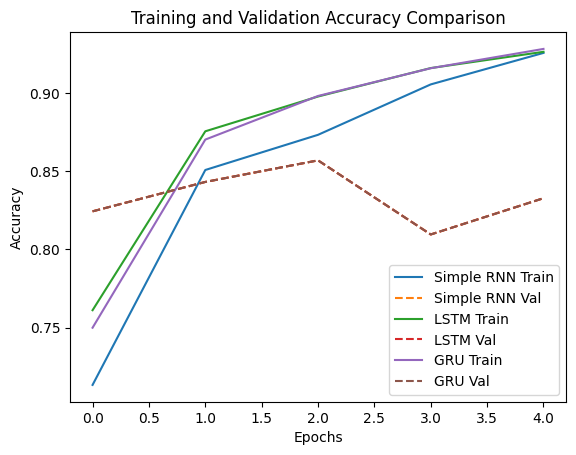

In [9]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='Simple RNN Train')
plt.plot(history.history['val_accuracy'],'--', label='Simple RNN Val')
plt.plot(history_lstm.history['accuracy'], label='LSTM Train')
plt.plot(history.history['val_accuracy'],'--', label='LSTM Val')
plt.plot(history_gru.history['accuracy'], label='GRU Train')
plt.plot(history.history['val_accuracy'],'--', label='GRU Val')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy Comparison')
plt.legend()
plt.show()